# 🛒 Predicting "Buy it again": which products will an Instacart customer reorder?

**Author:** Krish Makhija · **Tools:** Python, pandas, LightGBM, Optuna · **Data:** Instacart Online Grocery Shopping Dataset 2017 (3.4M real orders)

## The business question
Every grocery app (Instacart, Blinkit, Zepto, Instamart) shows a **"Buy it again"** list. If the list shows the right products, customers fill their basket faster and buy more. If it shows the wrong ones, the space is wasted.

**Goal:** for each customer, predict which of the products they've bought before will be in their **next** order, then use those predictions to build a better top-10 "Buy it again" list.

## How this notebook is organised
1. Load the data
2. Decide which data we can use (and why)
3. Explore the data (charts)
4. Split customers into train / validation / test (by customer, not by row)
5. Build features using **only the past** (no leakage)
6. Baseline: "reorder what was in the last order"
7. Model: LightGBM, tuned with Optuna
8. Choose the decision threshold on validation, then test **once**
9. Business result: a better top-10 "Buy it again" list
10. What drives reorders (feature importance)
11. Save results

## 1 · Load the data
`kagglehub` downloads the public Kaggle copy of Instacart's dataset. `dtype=` uses small number types so the 32-million-row table fits in Colab's memory.

In [ ]:
!pip -q install optuna kagglehub

In [ ]:
import kagglehub
path = kagglehub.dataset_download("psparks/instacart-market-basket-analysis")
print("Data folder:", path)

Using Colab cache for faster access to the 'instacart-market-basket-analysis' dataset.
Data folder: /kaggle/input/instacart-market-basket-analysis


In [ ]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
warnings.filterwarnings("ignore")

SEED = 42
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

orders = pd.read_csv(f"{path}/orders.csv", dtype={
    "order_id": "int32", "user_id": "int32", "eval_set": "category", "order_number": "int16",
    "order_dow": "int8", "order_hour_of_day": "int8", "days_since_prior_order": "float32"})
prior = pd.read_csv(f"{path}/order_products__prior.csv", dtype={
    "order_id": "int32", "product_id": "int32", "add_to_cart_order": "int16", "reordered": "int8"})
train_items = pd.read_csv(f"{path}/order_products__train.csv", dtype={
    "order_id": "int32", "product_id": "int32", "add_to_cart_order": "int16", "reordered": "int8"})
products = pd.read_csv(f"{path}/products.csv")
aisles = pd.read_csv(f"{path}/aisles.csv")
departments = pd.read_csv(f"{path}/departments.csv")
products = products.merge(aisles, on="aisle_id").merge(departments, on="department_id")

for name, df in [("orders", orders), ("prior", prior), ("train_items", train_items), ("products", products)]:
    print(f"{name:<12} {df.shape[0]:>11,} rows")
print(orders["eval_set"].value_counts())

orders         3,421,083 rows
prior         32,434,489 rows
train_items    1,384,617 rows
products          49,688 rows
eval_set
prior    3214874
train     131209
test       75000
Name: count, dtype: int64


## 2 · Which data can we use?
- **prior** = each customer's past orders → the history we learn from.
- **train** = each customer's latest order **with the answer** (what they bought) → our labels.
- **test** = 75,000 latest orders whose answers Kaggle kept hidden → **we drop these customers**, because we can't check predictions without answers.

So the project uses the **131,209 customers who have a known latest order**. We make our own test set from them later (Section 4).

`days_since_prior_order` is empty (NaN) for each customer's first order. That's **meaningful**: there was no earlier order. We keep it as NaN. Values of 30 mean "30 or more days", because the dataset caps them.

In [ ]:
labelled_users = orders.loc[orders["eval_set"] == "train", "user_id"].unique()
orders = orders[orders["user_id"].isin(labelled_users) & (orders["eval_set"] != "test")].copy()
orders["eval_set"] = orders["eval_set"].astype(str)
orders = orders.sort_values(["user_id", "order_number"]).reset_index(drop=True)

# cumulative days since each customer's first order (first order = day 0)
orders["cum_days"] = orders["days_since_prior_order"].fillna(0).groupby(orders["user_id"]).cumsum().astype("float32")

prior = prior[prior["order_id"].isin(orders["order_id"])]
po = prior.merge(orders[["order_id", "user_id", "order_number", "order_dow", "order_hour_of_day", "cum_days"]], on="order_id")
del prior

print(f"Customers: {orders['user_id'].nunique():,}")
print(f"Past orders: {(orders['eval_set'] == 'prior').sum():,} · past items bought: {len(po):,}")

Customers: 131,209
Past orders: 2,047,377 · past items bought: 20,641,991


## 3 · Explore the data
Four quick questions: **when** do people order, **how often**, **what** do they reorder, and **which products** are most popular?

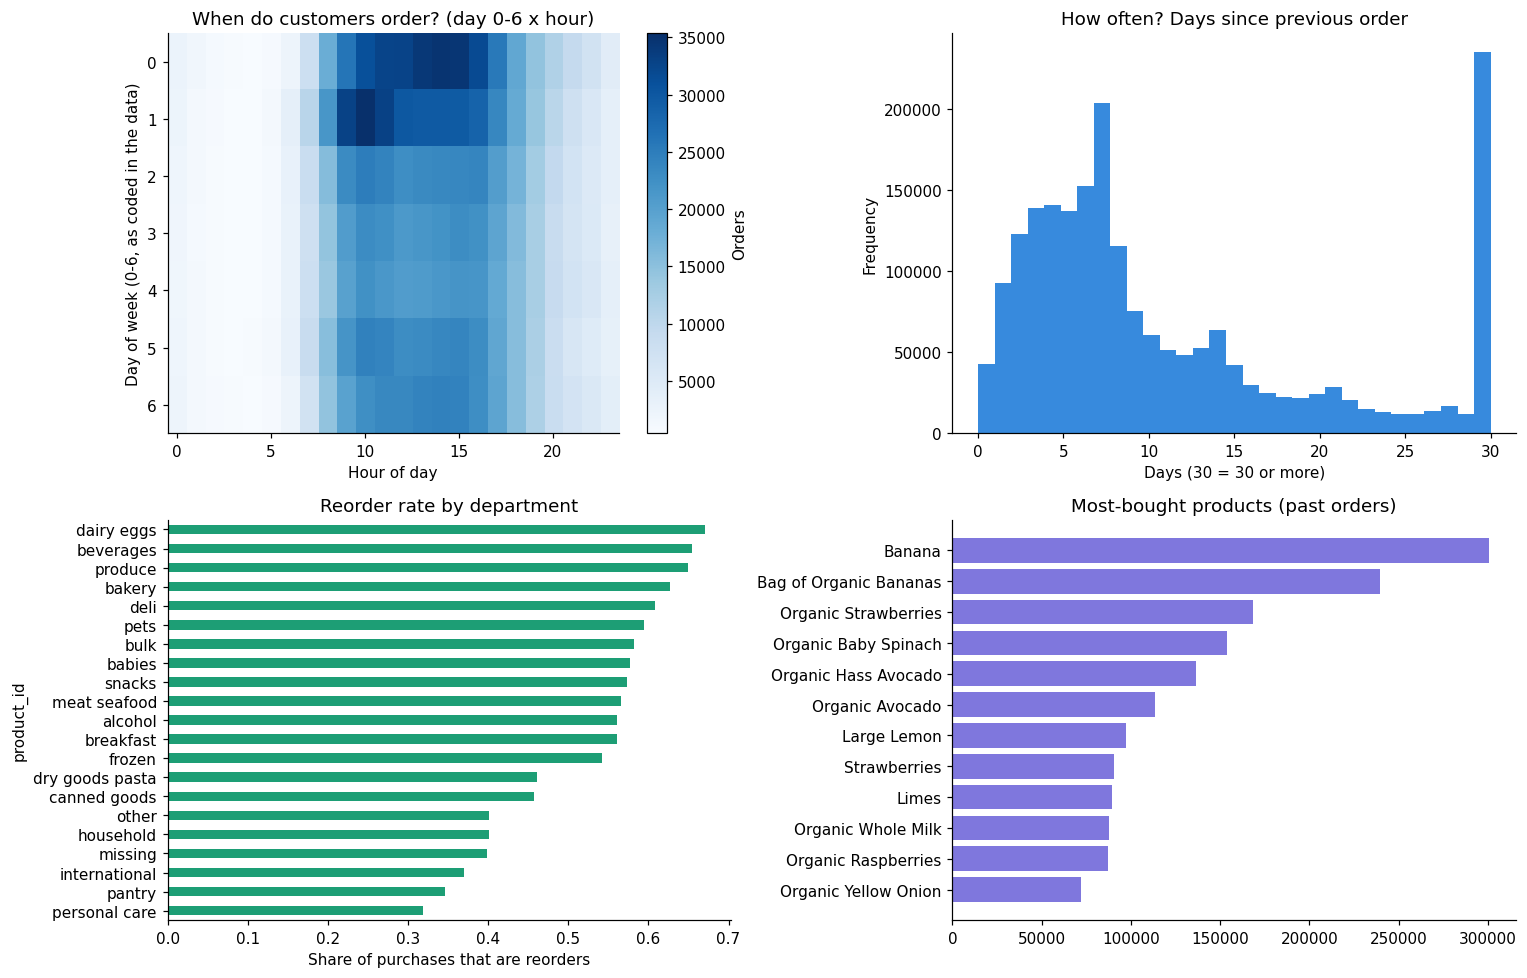

Overall reorder rate in past orders: 58.9%
Median days between orders: 7


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 3a. when: orders by day of week x hour
heat = orders.pivot_table(index="order_dow", columns="order_hour_of_day", values="order_id", aggfunc="count").fillna(0)
im = axes[0, 0].imshow(heat, aspect="auto", cmap="Blues")
axes[0, 0].set_title("When do customers order? (day 0-6 x hour)")
axes[0, 0].set_xlabel("Hour of day"); axes[0, 0].set_ylabel("Day of week (0-6, as coded in the data)")
fig.colorbar(im, ax=axes[0, 0], label="Orders")

# 3b. how often: days between orders
orders["days_since_prior_order"].dropna().plot.hist(bins=31, ax=axes[0, 1], color="#378ADD")
axes[0, 1].set_title("How often? Days since previous order")
axes[0, 1].set_xlabel("Days (30 = 30 or more)")

# 3c. what gets reordered: reorder rate by department
dept = po["reordered"].groupby(po["product_id"].map(products.set_index("product_id")["department"])).mean().sort_values()
dept.plot.barh(ax=axes[1, 0], color="#1D9E75")
axes[1, 0].set_title("Reorder rate by department"); axes[1, 0].set_xlabel("Share of purchases that are reorders")

# 3d. top products
top = po["product_id"].value_counts().head(12).rename_axis("product_id").reset_index(name="times")
top = top.merge(products[["product_id", "product_name"]], on="product_id").sort_values("times")
axes[1, 1].barh(top["product_name"].str[:28], top["times"], color="#7F77DD")
axes[1, 1].set_title("Most-bought products (past orders)")

plt.tight_layout(); plt.savefig(f"{OUT}/eda_overview.png", bbox_inches="tight"); plt.show()

print(f"Overall reorder rate in past orders: {po['reordered'].mean():.1%}")
print(f"Median days between orders: {orders['days_since_prior_order'].median():.0f}")

## 4 · Split customers into train / validation / test
**Why split by customer?** If the same customer appeared in both train and test, the model would partly be tested on someone it has already studied. That's **train-test contamination** (4.1 item 5). So each customer goes into exactly one pile:

| Pile | Share of customers | Used for |
|---|---|---|
| Train | 70% | learning |
| Validation | 15% | tuning, early stopping and choosing the threshold |
| Test | 15% | the final, honest score, used **once** |

In [ ]:
rng = np.random.default_rng(SEED)
users = rng.permutation(orders["user_id"].unique())
n = len(users)
split_of = pd.Series("train", index=users)
split_of.iloc[int(0.70 * n):int(0.85 * n)] = "valid"
split_of.iloc[int(0.85 * n):] = "test"
print(split_of.value_counts())

train    91846
test     19682
valid    19681
Name: count, dtype: int64


## 5 · Build features using only the past
Each row = one **(customer, product they've bought before)** pair. Label `y = 1` if that product is in the customer's next (target) order.

**Leakage rules we follow**
- Every feature comes from **past orders only** (`prior`), never from the target order's basket.
- From the target order we use only what the app knows **before** the customer shops: day, hour and days since their last order.
- Product, aisle and department statistics are computed **on training customers only**, so validation and test customers never leak into them.

| Group | Features (in plain English) |
|---|---|
| Customer | number of past orders, average basket size, how often they reorder, average gap between orders |
| Product | how popular, how often it is reordered, average position in the cart, aisle and department reorder rates |
| Customer x product | times bought, share of their orders that include it, orders and days since they last bought it, whether it was in their last order |
| Order context | day of week, hour, days since previous order |

In [ ]:
t0 = time.time()
prior_orders = orders[orders["eval_set"] == "prior"]
target = orders[orders["eval_set"] == "train"][["order_id", "user_id", "order_dow", "order_hour_of_day",
                                                "days_since_prior_order", "cum_days"]]
target.columns = ["target_order_id", "user_id", "t_dow", "t_hour", "t_days_since_prior", "t_cum_days"]

# customer features
u = prior_orders.groupby("user_id").agg(u_n_orders=("order_number", "max"),
                                        u_avg_gap=("days_since_prior_order", "mean"))
u2 = po.groupby("user_id").agg(u_items=("product_id", "size"), u_distinct=("product_id", "nunique"),
                               u_reorder_ratio=("reordered", "mean"))
u = u.join(u2)
u["u_avg_basket"] = u["u_items"] / u["u_n_orders"]

# product / aisle / department features: training customers only
po_tr = po[po["user_id"].map(split_of).eq("train")].copy()
pinfo = products.set_index("product_id")
po_tr["aisle_id"] = po_tr["product_id"].map(pinfo["aisle_id"])
po_tr["department_id"] = po_tr["product_id"].map(pinfo["department_id"])
p = po_tr.groupby("product_id").agg(p_orders=("order_id", "size"), p_reorder_rate=("reordered", "mean"),
                                     p_avg_cart_pos=("add_to_cart_order", "mean"), p_users=("user_id", "nunique"))
a = po_tr.groupby("aisle_id")["reordered"].mean().rename("aisle_reorder_rate")
d = po_tr.groupby("department_id")["reordered"].mean().rename("dept_reorder_rate")
del po_tr

# customer x product features
up = po.groupby(["user_id", "product_id"]).agg(up_times=("order_id", "size"), up_first=("order_number", "min"),
                                               up_last=("order_number", "max"), up_avg_cart_pos=("add_to_cart_order", "mean"),
                                               up_last_cum_days=("cum_days", "max")).reset_index()

df = (up.merge(u, on="user_id")
        .merge(target, on="user_id")
        .merge(products[["product_id", "aisle_id", "department_id"]], on="product_id")
        .merge(p, on="product_id", how="left")
        .merge(a, on="aisle_id", how="left")
        .merge(d, on="department_id", how="left"))
del up

df["up_order_rate"] = df["up_times"] / df["u_n_orders"]
df["up_rate_since_first"] = df["up_times"] / (df["u_n_orders"] - df["up_first"] + 1)
df["up_orders_since_last"] = df["u_n_orders"] - df["up_last"]
df["up_in_last_order"] = (df["up_last"] == df["u_n_orders"]).astype("int8")
df["up_days_since_last"] = df["t_cum_days"] - df["up_last_cum_days"]
df["up_days_vs_gap"] = df["up_days_since_last"] / (df["u_avg_gap"] + 1)

# label: is the product in the target order?
lab = train_items[["order_id", "product_id"]].rename(columns={"order_id": "target_order_id"}).assign(y=1)
df = df.merge(lab, on=["target_order_id", "product_id"], how="left")
df["y"] = df["y"].fillna(0).astype("int8")
df["split"] = df["user_id"].map(split_of)

FEATURES = ["u_n_orders", "u_avg_gap", "u_items", "u_distinct", "u_reorder_ratio", "u_avg_basket",
            "p_orders", "p_reorder_rate", "p_avg_cart_pos", "p_users", "aisle_reorder_rate", "dept_reorder_rate",
            "up_times", "up_order_rate", "up_rate_since_first", "up_orders_since_last", "up_in_last_order",
            "up_avg_cart_pos", "up_days_since_last", "up_days_vs_gap",
            "t_dow", "t_hour", "t_days_since_prior"]
df[FEATURES] = df[FEATURES].astype("float32")

print(f"Rows (customer x product pairs): {len(df):,} · features: {len(FEATURES)} · built in {time.time()-t0:.0f}s")
print(f"Share of pairs reordered (positive class): {df['y'].mean():.1%}  <- imbalanced")
print(df.groupby("split")["y"].agg(["size", "mean"]))

Rows (customer x product pairs): 8,474,661 · features: 23 · built in 38s
Share of pairs reordered (positive class): 9.8%  <- imbalanced
          size      mean
split                   
test   1259136  0.097376
train  5948711  0.097650
valid  1266814  0.098929


## 6 · Baseline: "reorder what was in the last order"
Before any model, set the bar with the simplest sensible rule (4.1 item 2): **predict a reorder for every product in the customer's last order.** The model is only worth it if it clearly beats this.

**Metrics**
- **Precision:** of the products we predicted, how many were actually reordered?
- **Recall:** of the products actually reordered, how many did we catch?
- **F1:** the balance of the two.
- **Mean per-order F1:** F1 for each customer's order, averaged. This is how a real "Buy it again" list is judged, one customer at a time. (If a customer reorders nothing and we predict nothing, that order counts as perfect.)

In [ ]:
def mean_order_f1(frame, pred):
    t = pd.DataFrame({"user_id": frame["user_id"].values, "y": frame["y"].values, "p": np.asarray(pred).astype(int)})
    t["tp"] = t["y"] * t["p"]
    g = t.groupby("user_id")[["tp", "p", "y"]].sum()
    prec = np.where(g["p"] > 0, g["tp"] / g["p"].clip(lower=1), 0)
    rec = np.where(g["y"] > 0, g["tp"] / g["y"].clip(lower=1), 0)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-9), 0)
    f1 = np.where((g["p"] == 0) & (g["y"] == 0), 1.0, f1)
    return float(f1.mean())

def scorecard(frame, pred, name):
    return {"model": name,
            "precision": precision_score(frame["y"], pred, zero_division=0),
            "recall": recall_score(frame["y"], pred, zero_division=0),
            "f1": f1_score(frame["y"], pred, zero_division=0),
            "mean_order_f1": mean_order_f1(frame, pred)}

tr, va, te = (df[df["split"] == s] for s in ["train", "valid", "test"])
base_test = scorecard(te, te["up_in_last_order"], "Baseline: last order")
pd.DataFrame([base_test]).round(4)

,model,precision,recall,f1,mean_order_f1
0,Baseline: last order,0.2789,0.4604,0.3474,0.3121


## 7 · Model: LightGBM tuned with Optuna
**LightGBM** builds many small decision trees, each one fixing the mistakes of the ones before. It's fast on millions of rows and doesn't need scaling (4.1 item 6).

**Tuning (4.1 item 9):** Optuna tries hyperparameter combinations "hot-or-cold" style. To keep it fast it tunes on a **sample of training customers** and scores each try on the **validation** customers. The test set stays locked.
`scale_pos_weight` is one of the tuned settings: it makes missing a reorder cost more, which is how we handle the **imbalanced** classes (4.1 item 8).

In [ ]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 15          # raise for a longer, more thorough search
TUNE_USER_SHARE = 0.3  # share of training customers used while tuning

tune_users = tr["user_id"].drop_duplicates().sample(frac=TUNE_USER_SHARE, random_state=SEED)
tr_tune = tr[tr["user_id"].isin(tune_users)]
d_tune = lgb.Dataset(tr_tune[FEATURES], tr_tune["y"], free_raw_data=False)
d_val = lgb.Dataset(va[FEATURES], va["y"], reference=d_tune, free_raw_data=False)

BASE = {"objective": "binary", "metric": "auc", "verbose": -1, "seed": SEED, "bagging_freq": 1, "num_threads": 0}

def objective(trial):
    params = {**BASE,
              "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.15, log=True),
              "num_leaves": trial.suggest_int("num_leaves", 31, 255, log=True),
              "min_child_samples": trial.suggest_int("min_child_samples", 20, 400, log=True),
              "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
              "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
              "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 10, log=True),
              "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 5.0)}
    m = lgb.train(params, d_tune, num_boost_round=1000, valid_sets=[d_val],
                  callbacks=[lgb.early_stopping(30, verbose=False)])
    return m.best_score["valid_0"]["auc"]

t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)
print(f"Best validation AUC while tuning: {study.best_value:.4f} ({time.time()-t0:.0f}s)")
print("Best settings:", {k: round(v, 4) for k, v in study.best_params.items()})

**Note:** tuning was stopped manually after **9 of the 15 planned trials** to fit the time limits of free Colab. The trials that finished are kept, and the best one is used below.

In [ ]:
print("Tries finished:", len([t for t in study.trials if t.value is not None]))
print("Best AUC so far:", round(study.best_value, 4))

Tries finished: 9
Best AUC so far: 0.8341


In [ ]:
# final model: best settings, ALL training customers, early stopping on validation
best = {**BASE, **study.best_params}
d_tr = lgb.Dataset(tr[FEATURES], tr["y"])
d_va = lgb.Dataset(va[FEATURES], va["y"], reference=d_tr)
t0 = time.time()
model = lgb.train(best, d_tr, num_boost_round=3000, valid_sets=[d_va],
                  callbacks=[lgb.early_stopping(50), lgb.log_evaluation(200)])
print(f"Trees: {model.best_iteration} · trained in {time.time()-t0:.0f}s")
va_prob = model.predict(va[FEATURES], num_iteration=model.best_iteration)

Training until validation scores don't improve for 50 rounds
[200]	valid_0's auc: 0.834322
[400]	valid_0's auc: 0.834931
[600]	valid_0's auc: 0.835102
[800]	valid_0's auc: 0.835201
[1000]	valid_0's auc: 0.835237
Early stopping, best iteration is:
[967]	valid_0's auc: 0.835241
Trees: 967 · trained in 933s


## 8 · Choose the threshold on validation, then test once
The model outputs a **probability** of reorder. We need a cut-off: above it, the product goes on the list. We pick the cut-off that gives the best **mean per-order F1 on validation**, never on test. Then we score the test set **one time**.

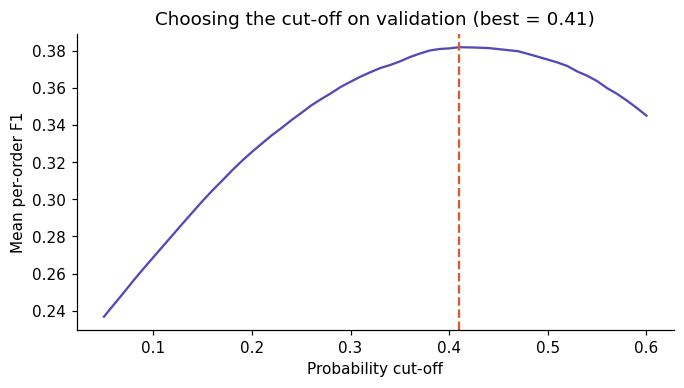

Threshold chosen on validation: 0.41
Mean per-order F1: baseline 0.312 -> model 0.381 (+22%)


,precision,recall,f1,mean_order_f1,roc_auc,pr_auc
model,,,,,,
Baseline: last order,0.2789,0.4604,0.3474,0.3121,0.6660,0.1810
LightGBM (tuned),0.3644,0.5636,0.4426,0.3809,0.8375,0.4303


In [ ]:
grid = np.round(np.arange(0.05, 0.61, 0.01), 2)
f1s = [mean_order_f1(va, va_prob >= t) for t in grid]
THRESH = float(grid[int(np.argmax(f1s))])

plt.figure(figsize=(7, 3.5))
plt.plot(grid, f1s, color="#534AB7"); plt.axvline(THRESH, ls="--", color="#D85A30")
plt.title(f"Choosing the cut-off on validation (best = {THRESH})")
plt.xlabel("Probability cut-off"); plt.ylabel("Mean per-order F1")
plt.savefig(f"{OUT}/threshold_choice.png", bbox_inches="tight"); plt.show()

# ---- the one and only look at the test set ----
te_prob = model.predict(te[FEATURES], num_iteration=model.best_iteration)
model_test = scorecard(te, te_prob >= THRESH, "LightGBM (tuned)")
model_test["roc_auc"] = roc_auc_score(te["y"], te_prob)
model_test["pr_auc"] = average_precision_score(te["y"], te_prob)
base_test["roc_auc"] = roc_auc_score(te["y"], te["up_in_last_order"])
base_test["pr_auc"] = average_precision_score(te["y"], te["up_in_last_order"])

results = pd.DataFrame([base_test, model_test]).set_index("model")
lift = model_test["mean_order_f1"] / base_test["mean_order_f1"] - 1
print(f"Threshold chosen on validation: {THRESH}")
print(f"Mean per-order F1: baseline {base_test['mean_order_f1']:.3f} -> model {model_test['mean_order_f1']:.3f} ({lift:+.0%})")
results.round(4)

## 9 · Business result: a better top-10 "Buy it again" list
Apps show a **fixed-length list**, so the real question is: *if we show each customer 10 products, how many of the products they'll actually reorder are on it?*

We compare three ways of ranking a customer's past products:
1. **Most recent first:** products from the last order, then earlier ones
2. **Most frequent first:** the products they've bought most often (a common default)
3. **Model:** ranked by the model's reorder probability

**Metrics (test customers who reordered at least one product):**
- **Recall@10:** share of their actual reorders that appear in their top 10
- **Hit rate@10:** share of customers with at least one correct product in their top 10

                     recall@10  hit_rate@10
Most recent first       0.5282       0.8959
Most frequent first     0.5199       0.9037
Model                   0.5893       0.9335


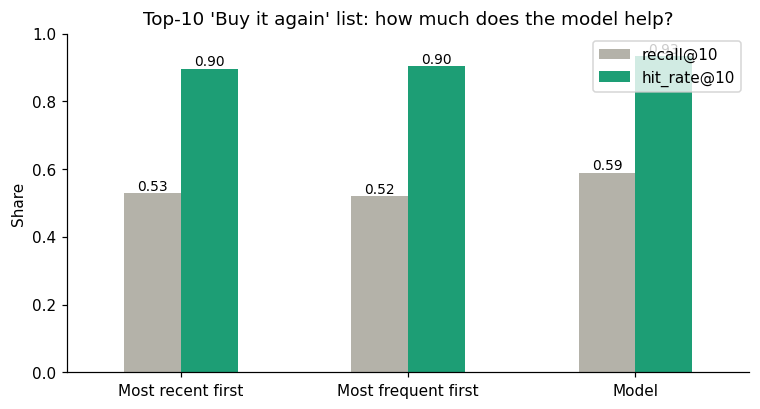

In [ ]:
def topk_metrics(frame, score, k=10):
    t = frame[["user_id", "y"]].copy()
    t["s"] = np.asarray(score)
    t = t.sample(frac=1, random_state=SEED)  # break ties randomly
    t["rank"] = t.groupby("user_id")["s"].rank(method="first", ascending=False)
    top = t[t["rank"] <= k].groupby("user_id")["y"].sum()
    total = t.groupby("user_id")["y"].sum()
    keep = total > 0
    return {"recall@10": float((top[keep] / total[keep]).mean()), "hit_rate@10": float((top[keep] > 0).mean())}

recency_score = -te["up_orders_since_last"].values + te["up_times"].values / 1000  # last order first, ties by frequency
freq_score = te["up_times"].values + te["up_order_rate"].values / 1000
topk = pd.DataFrame({"Most recent first": topk_metrics(te, recency_score),
                     "Most frequent first": topk_metrics(te, freq_score),
                     "Model": topk_metrics(te, te_prob)}).T
print(topk.round(4))

ax = topk.plot.bar(rot=0, figsize=(8, 4), color=["#B4B2A9", "#1D9E75"])
ax.set_title("Top-10 'Buy it again' list: how much does the model help?")
ax.set_ylabel("Share"); ax.set_ylim(0, 1)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=9)
plt.savefig(f"{OUT}/buy_it_again_top10.png", bbox_inches="tight"); plt.show()

## 10 · What drives reorders?
Two views (4.1 item 7):
- **Gain importance:** how much each feature improved the trees while training.
- **Permutation importance:** shuffle one feature on test data and measure how much the AUC drops. It's more honest, because it shows what the model really relies on.

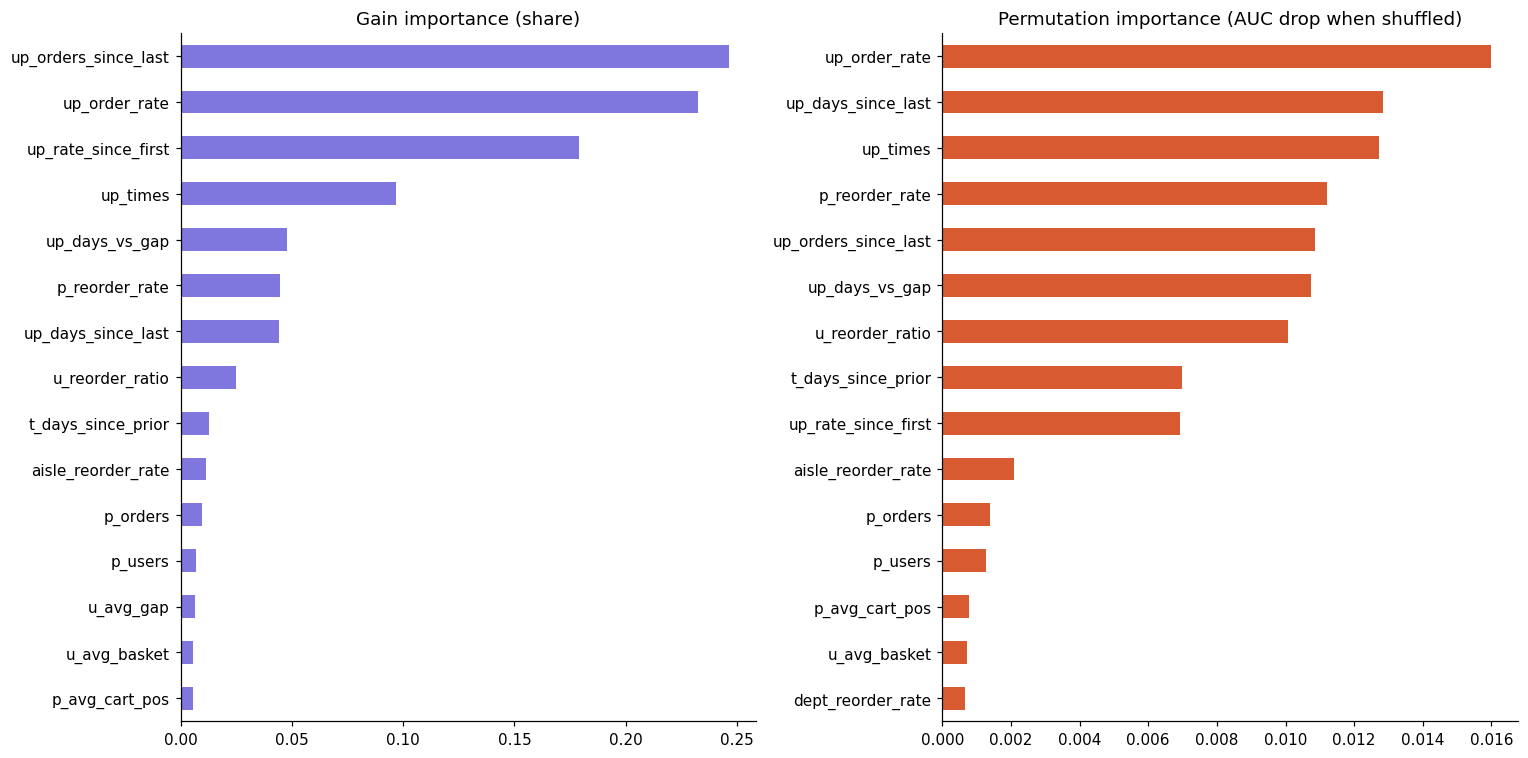

In [14]:
gain = pd.Series(model.feature_importance("gain"), index=FEATURES).sort_values()
samp = te.sample(n=min(300_000, len(te)), random_state=SEED)
base_auc = roc_auc_score(samp["y"], model.predict(samp[FEATURES], num_iteration=model.best_iteration))
perm = {}
rs = np.random.default_rng(SEED)
for f in FEATURES:
    shuffled = samp[FEATURES].copy()
    shuffled[f] = rs.permutation(shuffled[f].values)
    perm[f] = base_auc - roc_auc_score(samp["y"], model.predict(shuffled, num_iteration=model.best_iteration))
perm = pd.Series(perm).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
(gain / gain.sum()).tail(15).plot.barh(ax=axes[0], color="#7F77DD"); axes[0].set_title("Gain importance (share)")
perm.tail(15).plot.barh(ax=axes[1], color="#D85A30"); axes[1].set_title("Permutation importance (AUC drop when shuffled)")
plt.tight_layout(); plt.savefig(f"{OUT}/feature_importance.png", bbox_inches="tight"); plt.show()

## 11 · Save results
Saves the model, metrics and charts in the `outputs/` folder, and prints a summary to paste into the README.

In [15]:
model.save_model(f"{OUT}/lgbm_reorder_model.txt", num_iteration=model.best_iteration)
summary = {
    "customers": int(df["user_id"].nunique()), "pairs": int(len(df)), "positive_rate": float(df["y"].mean()),
    "threshold": THRESH, "best_params": study.best_params, "trees": int(model.best_iteration),
    "test_results": results.reset_index().to_dict("records"),
    "top10": topk.reset_index(names="ranking").to_dict("records"),
    "top_features_permutation": perm.sort_values(ascending=False).head(8).round(5).to_dict(),
}
with open(f"{OUT}/results.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
print(json.dumps(summary, indent=2, default=float))

{
  "customers": 131209,
  "pairs": 8474661,
  "positive_rate": 0.09780025419305857,
  "threshold": 0.41,
  "best_params": {
    "learning_rate": 0.03755115322842063,
    "num_leaves": 57,
    "min_child_samples": 59,
    "feature_fraction": 0.728034992108518,
    "bagging_fraction": 0.8925879806965068,
    "lambda_l2": 0.006290644294586149,
    "scale_pos_weight": 3.0569377536544464
  },
  "trees": 967,
  "test_results": [
    {
      "model": "Baseline: last order",
      "precision": 0.27890558226165835,
      "recall": 0.4604273713400212,
      "f1": 0.3473827683920017,
      "mean_order_f1": 0.3121209237017012,
      "roc_auc": 0.6660022202041963,
      "pr_auc": 0.18095734816314005
    },
    {
      "model": "LightGBM (tuned)",
      "precision": 0.3643539194027175,
      "recall": 0.5636000326237665,
      "f1": 0.44258635983719163,
      "mean_order_f1": 0.380891862715451,
      "roc_auc": 0.8375200852367379,
      "pr_auc": 0.4302878576304623
    }
  ],
  "top10": [
    {
   

In [ ]:
import shutil
from google.colab import files
shutil.make_archive("instacart_outputs", "zip", OUT)
files.download("instacart_outputs.zip")